In [1]:
import jax

import matplotlib.pyplot as plt

from agfx.gym import create_state, enumerate_ancestral_graphs
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet
from agfx.evals import eval_marginal

In [2]:
num_nodes = 5
bs = 64
dmid = 64

iterations = int(4e4)
logr_t = LogRewardType.SPARSE
loss_t = LossType.CB

seed = 42
alphas = [.1, .5, 1, 1.5, 2]

key = jax.random.key(seed)
k1, k2, k3 = jax.random.split(key, 3)

In [3]:
all_graphs = enumerate_ancestral_graphs(num_nodes)

In [4]:
def run(alpha: float):
    state = create_state(bs, num_nodes)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid)
    
    # Create the reward function
    logr = create_log_reward(logr_t, alpha=alpha)

    gfn, losses = train(gfn, state, k2, logr, iterations, loss_t)
    
    true_marginals, estimated_marginals = eval_marginal(gfn, state, logr, all_graphs, k3)

    return true_marginals, estimated_marginals

In [5]:
tmarg = []
emarg = [] 

for alpha in alphas:
    tmarg_alpha, emarg_alpha = run(alpha=alpha)

    tmarg.append(tmarg_alpha)
    emarg.append(emarg_alpha)

100%|██████████| 40000/40000 [01:38<00:00, 406.09it/s, loss=1.74e-01]


true [[0.3331943  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600438 0.20600438 0.2547959 ]
 [0.3331943  0.20600438 0.20600438 0.2547959 ]
 [0.3331946  0.20600459 0.20600459 0.2547959 ]
 [0.3331946  0.20600459 0.20600459 0.2547959 ]]
estimated [[0.34078124 0.20234375 0.20359375 0.25328124]
 [0.32999998 0.20343749 0.21187499 0.2546875 ]
 [0.33046874 0.20468749 0.20671874 0.258125  ]
 [0.33828124 0.19921875 0.20796874 0.25453123]
 [0.33499998 0.19156249 0.20703125 0.26640624]
 [0.34890625 0.2015625  0.19796875 0.2515625 ]
 [0.33765623 0.20328124 0.20359375 0.25546876]
 [0.339375   0.20171875 0.19999999 0.25890625]
 [0.33734375 0.200625   0.20046875 0.2615625 ]
 [0.33453125 0.20593749 0.19578125 0.26375   ]]


100%|██████████| 40000/40000 [01:31<00:00, 436.52it/s, loss=8.81e-02]


true [[0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987772]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]
 [0.34383526 0.20314372 0.20314372 0.24987796]]
estimated [[0.35171875 0.19296874 0.20546874 0.24984375]
 [0.33984375 0.20203124 0.206875   0.25125   ]
 [0.340625   0.20078124 0.20453125 0.2540625 ]
 [0.3478125  0.19484374 0.2015625  0.25578123]
 [0.34265625 0.19687499 0.2025     0.25796875]
 [0.35343748 0.2003125  0.20234375 0.24390624]
 [0.3421875  0.19734375 0.20609374 0.25437498]
 [0.34515625 0.1971875  0.20421875 0.2534375 ]
 [0.3478125  0.1965625  0.20531249 0.2503125 ]
 [0.33609375 0.2090625  0.20015624 0.2546875 ]]


100%|██████████| 40000/40000 [01:34<00:00, 425.19it/s, loss=9.73e-02]


true [[0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935863 0.19935863 0.24347019]
 [0.35781282 0.19935882 0.19935882 0.24347019]
 [0.35781282 0.19935882 0.19935863 0.24347019]
 [0.35781282 0.19935882 0.19935882 0.24347019]]
estimated [[0.36374998 0.18734375 0.205625   0.24328125]
 [0.3540625  0.19578125 0.20328124 0.24687499]
 [0.3553125  0.19140625 0.205625   0.24765624]
 [0.36296874 0.193125   0.20203124 0.241875  ]
 [0.35953125 0.1925     0.19703124 0.2509375 ]
 [0.3765625  0.194375   0.19156249 0.2375    ]
 [0.35718748 0.19546874 0.20578125 0.2415625 ]
 [0.35984373 0.19687499 0.1971875  0.24609375]
 [0.35468748 0.19734375 0.205      0.24296874]
 [0.35640624 0.20203124 0.1946875  0.24687499]]


100%|██████████| 40000/40000 [01:38<00:00, 405.44it/s, loss=8.02e-02]


true [[0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]
 [0.37264884 0.19530664 0.19530664 0.2367379 ]]
estimated [[0.384375   0.18187499 0.19375    0.24      ]
 [0.375      0.18484375 0.19999999 0.24015625]
 [0.37562498 0.186875   0.19734375 0.24015625]
 [0.3809375  0.1853125  0.19765624 0.23609374]
 [0.37484375 0.1871875  0.1959375  0.24203125]
 [0.38875    0.18734375 0.19171874 0.2321875 ]
 [0.36734375 0.18984374 0.2075     0.23531249]
 [0.38140625 0.1875     0.18984374 0.24125   ]
 [0.37328124 0.1934375  0.19296874 0.2403125 ]
 [0.36859375 0.19234374 0.193125   0.2459375 ]]


100%|██████████| 40000/40000 [01:37<00:00, 412.29it/s, loss=9.82e-02]


true [[0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]
 [0.3885007  0.190936   0.190936   0.22962806]]
estimated [[0.39093748 0.18078125 0.1925     0.23578124]
 [0.389375   0.1834375  0.19703124 0.23015624]
 [0.3915625  0.18453124 0.19203125 0.23187499]
 [0.395625   0.18249999 0.193125   0.22874999]
 [0.39078125 0.18187499 0.19125    0.23609374]
 [0.40390623 0.18374999 0.1871875  0.22515625]
 [0.38703123 0.18609375 0.19484374 0.23203124]
 [0.3921875  0.1853125  0.1871875  0.23531249]
 [0.38734373 0.19234374 0.19078125 0.22953124]
 [0.3821875  0.18906249 0.18921874 0.23953125]]


In [9]:
from mpl_preamble import *

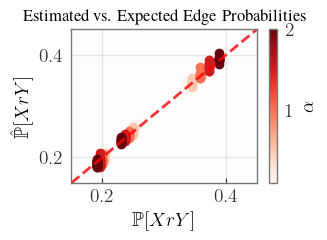

In [26]:
fig, ax = plt.subplots(figsize=(3, 2))
cmap = plt.cm.Reds
norm = plt.Normalize(min(alphas), max(alphas))

for t, e, a in zip(tmarg, emarg, alphas):
    ax.scatter(t, e, color=cmap(norm(a)), label=a)

fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, label='$\\alpha$')
ax.axline((0, 0), slope=1, linestyle="--", color="red", alpha=.8)

lim = .15, .45 
ax.set_xlim(*lim)
ax.set_ylim(*lim)

ax.set_xlabel("$\\mathbb{P}[XrY]$")
ax.set_ylabel("$\\hat{\\mathbb{P}}[XrY]$")
ax.set_title("Estimated vs. Expected Edge Probabilities", size=12)
plt.savefig("figures/sparse_edges.pdf", bbox_inches="tight")